# Анализ кредитных клиентов: связь истории платежей с просрочкой

**Исследовательский вопрос:** какие группы истории платежей связаны с последующей просрочкой?

**Данные:** `24_credit.csv` (информация о клиентах, их кредитных лимитах, истории статусов платежей за 6 месяцев, суммах счетов и фактических платежах).

**План:** загрузка → проверка → создание производных признаков → описательная статистика → группировки по истории платежей → статистические тесты → графики → итоговый вывод.

**Выполнила:** Евстафьева Вера (пара в сб 9.45)

## 1. Импорты бибилиотек и настройка:

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

FILE = Path("24_credit.csv")

## 2. Загрузка данных и первичный осмотр

In [2]:
df = pd.read_csv(FILE)
print(f"Размер: {df.shape[0]:,} строк × {df.shape[1]} столбцов")
print("\nТипы данных:\n", df.dtypes.to_string())
print("\nПропуски:\n", df.isna().sum()[df.isna().sum() > 0].sort_values(ascending=False).to_string())
print("\nПолные дубликаты:", df.duplicated().sum())

preview_cols = [
    "ID", "LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE",
    "PAY_0", "BILL_AMT1", "PAY_AMT1", "default payment next month"
]
df[preview_cols].head()

Размер: 30,000 строк × 25 столбцов

Типы данных:
 ID                            int64
LIMIT_BAL                     int64
SEX                           int64
EDUCATION                     int64
MARRIAGE                      int64
AGE                           int64
PAY_0                         int64
PAY_2                         int64
PAY_3                         int64
PAY_4                         int64
PAY_5                         int64
PAY_6                         int64
BILL_AMT1                     int64
BILL_AMT2                     int64
BILL_AMT3                     int64
BILL_AMT4                     int64
BILL_AMT5                     int64
BILL_AMT6                     int64
PAY_AMT1                      int64
PAY_AMT2                      int64
PAY_AMT3                      int64
PAY_AMT4                      int64
PAY_AMT5                      int64
PAY_AMT6                      int64
default payment next month    int64

Пропуски:
 Series([], )

Полные дубликаты: 0


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,BILL_AMT1,PAY_AMT1,default payment next month
0,1,20000,2,2,1,24,2,3913,0,1
1,2,120000,2,2,2,26,-1,2682,0,1
2,3,90000,2,2,2,34,0,29239,1518,0
3,4,50000,2,2,1,37,0,46990,2000,0
4,5,50000,1,2,1,57,-1,8617,2000,0


Задача кредитного скоринга - бинарная классификации клиентов банка по факту просрочки в следующем месяце.

Датасет — 30 000 клиентов × 25 признаков трёх типов:

демография — SEX, EDUCATION, MARRIAGE, AGE, LIMIT_BAL;

история платежей PAY_0...PAY_6 — категориальные метки задержки (−2 нет потребления, −1 оплачено, 0 револьверный, 1..9 просрочка в месяцах) — ядро анализа;

финансы — суммы счетов BILL_AMT1..6 и платежей PAY_AMT1..6.

Данные: строка = клиент, каждый месяц истории — отдельный столбец. Все признаки int64, включая категориальные — их коды (SEX ∈ {1,2}, EDUCATION ∈ {1..6}, MARRIAGE ∈ {0..3}, PAY_X ∈ {−2..9}) суть номинальные метки, а не числа. Пропусков и дубликатов нет — данные готовы к анализу.

## 3. Описательная статистика

In [3]:
df = df.rename(columns={"PAY_0": "PAY_1"})

# Целевая переменная
df["is_default"] = df["default payment next month"].astype(bool)

# История платежей — теперь с 1 по 6
pay_cols = [f"PAY_{i}" for i in range(1, 7)]

# Признак "просрочка в любом месяце истории" (PAY_X >= 1)
df["ever_delinquent"] = (df[pay_cols] >= 1).any(axis=1)

# Количество месяцев с просрочкой в истории
df["n_delinquent_months"] = (df[pay_cols] >= 1).sum(axis=1)

# Суммарный долг и суммарные платежи за полгода
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
pay_amt_cols = [f"PAY_AMT{i}" for i in range(1, 7)]
df["total_bill"] = df[bill_cols].sum(axis=1)
df["total_paid"] = df[pay_amt_cols].sum(axis=1)
df["payment_ratio"] = df["total_paid"] / df["total_bill"].replace(0, np.nan)

df[["ID", "is_default", "ever_delinquent", "n_delinquent_months",
    "total_bill", "total_paid", "payment_ratio"]].head()

,ID,is_default,ever_delinquent,n_delinquent_months,total_bill,total_paid,payment_ratio
0,1,True,True,2,7704,689,0.089434
1,2,True,True,2,17077,5000,0.292791
2,3,False,False,0,101653,11018,0.108388
3,4,False,False,0,231334,8388,0.036259
4,5,False,False,0,109339,59049,0.540054


Создано три новых производных признака: ever_delinquent (была ли хоть одна просрочка за полгода), n_delinquent_months (сколько именно месяцев клиент был в просрочке) и payment_ratio (доля фактически оплаченного от выставленного долга). Эти признаки сворачивают разрозненные 6 месяцев истории в компактные поведенческие метрики - именно на них строятся все дальнейшие группировки и статистические тесты для ответа на вопрос о связи истории платежей с просрочкой.

In [4]:
df[["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1", "total_bill", "total_paid"]].describe(
    percentiles=[.05, .25, .5, .75, .90, .95, .99]
).round(2)

,LIMIT_BAL,AGE,BILL_AMT1,PAY_AMT1,total_bill,total_paid
count,30000.00,30000.00,30000.00,30000.00,30000.00,30000.00
mean,167484.32,35.49,51223.33,5663.58,269861.67,31651.39
std,129747.66,9.22,73635.86,16563.28,379564.33,60827.68
min,10000.00,21.00,-165580.00,0.00,-336259.00,0.00
5%,20000.00,23.00,0.00,0.00,1167.85,220.40
25%,50000.00,28.00,3558.75,1000.00,28688.00,6679.75
50%,140000.00,34.00,22381.50,2100.00,126311.00,14383.00
75%,240000.00,41.00,67091.00,5006.00,342626.50,33503.50
90%,360000.00,49.00,142133.70,10300.00,743599.40,71749.60
95%,430000.00,53.00,201203.05,18428.20,1046422.05,118317.05


In [5]:
pd.DataFrame({
    "доля клиентов с просрочкой": [df["is_default"].mean()],
    "число клиентов": [len(df)]
}, index=["default next month"]).round(3)

,доля клиентов с просрочкой,число клиентов
default next month,0.221,30000


В нашем датасете 30 000 клиентов, и 22.1% из них (6 630 человек) допустили просрочку в следующем месяце. Это наш главный показатель, который мы будем прогнозировать.

Финансовые данные показывают, что у большинства клиентов суммы сильно различаются. Средний кредитный лимит - около 167 тысяч, но у большинства он ниже (медиана 140 тысяч), так как есть клиенты с очень большими лимитами (до 1 млн). То же самое с долгами: у типичного клиента суммарный долг за полгода около 126 тысяч, но у некоторых он достигает нескольких миллионов. При этом люди в среднем платят гораздо меньше, чем им выставлено (медиана платежей — всего 14 тысяч), что означает, что многие пользуются кредитом постоянно и не гасят его полностью. Также в счетах встречаются отрицательные числа — это значит, что клиент переплатил или сделал возврат.

Возраст клиентов более предсказуем: большинству от 28 до 41 года, средний возраст - 35 лет.



## 4. Группировки

1. Группировка по статусу в последнем месяце (PAY_1)

In [6]:
pay0_summary = df.groupby("PAY_1").agg(
    n=("is_default", "size"),
    default_rate=("is_default", "mean"),
    median_limit=("LIMIT_BAL", "median")
).sort_index()
pay0_summary["default_rate_%"] = (pay0_summary["default_rate"] * 100).round(1)
pay0_summary

,n,default_rate,median_limit,default_rate_%
PAY_1,,,,
-2,2759,0.132294,230000.0,13.2
-1,5686,0.167781,200000.0,16.8
0,14737,0.128113,120000.0,12.8
1,3688,0.339479,120000.0,33.9
2,2667,0.691414,80000.0,69.1
3,322,0.757764,50000.0,75.8
4,76,0.684211,45000.0,68.4
5,26,0.500000,50000.0,50.0
6,11,0.545455,70000.0,54.5


Анализ по последнему месяцу (PAY_1) показывает четкую закономерность: если у клиента нет просрочек (от -2 до 0), вероятность невыплаты составляет 13–17%, но при появлении первой просрочки (1 месяц) она вырастает до 34%, а при задержке от 2 месяцев и более — достигает критических 69–78%.

2. Группировка по числу "плохих" месяцев в истории

In [7]:
n_delinq_summary = df.groupby("n_delinquent_months").agg(
    n=("is_default", "size"),
    default_rate=("is_default", "mean")
)
n_delinq_summary["default_rate_%"] = (n_delinq_summary["default_rate"] * 100).round(1)
n_delinq_summary

,n,default_rate,default_rate_%
n_delinquent_months,,,
0,19931,0.117104,11.7
1,4426,0.298238,29.8
2,1899,0.387572,38.8
3,1154,0.508666,50.9
4,951,0.573081,57.3
5,298,0.573826,57.4
6,1341,0.703207,70.3


Клиенты с безупречной историей (0 просрочек) имеют низкий риск невыплаты - всего 11.7%, но каждая дополнительная просрочка за полгода резко увеличивает его: уже при 1–2 месяцах он вырастает до 30–39%, а при 5–6 месяцах задержек превышает 57–70%. Это подтверждает, что накопленная история просрочек - ключевой фактор, определяющий надежность клиента.

3. Группировка по "типу" истории

In [8]:
def history_type(row):
    pays = row[pay_cols].values
    if (pays >= 1).any():
        if (pays >= 2).any():
            return "Серьёзная просрочка (≥2 мес.)"
        return "Умеренная просрочка (1 мес.)"
    if (pays == 0).any():
        return "Револьверный кредит, без просрочек"
    return "Все счета оплачены (−1/−2)"

df["history_type"] = df.apply(history_type, axis=1)

hist_summary = df.groupby("history_type").agg(
    n=("is_default", "size"),
    default_rate=("is_default", "mean"),
    mean_payment_ratio=("payment_ratio", "mean")
).sort_values("default_rate", ascending=False)
hist_summary["default_rate_%"] = (hist_summary["default_rate"] * 100).round(1)
hist_summary

,n,default_rate,mean_payment_ratio,default_rate_%
history_type,,,,
Серьёзная просрочка (≥2 мес.),8380,0.463007,0.210882,46.3
Умеренная просрочка (1 мес.),1689,0.249852,0.757553,25.0
Все счета оплачены (−1/−2),5195,0.142060,1.081485,14.2
"Револьверный кредит, без просрочек",14736,0.108306,0.239368,10.8


Тип истории платежей четко разделяет клиентов по уровню риска: самая уязвимая группа - с серьезными просрочками (≥2 мес.) имеет 46.3% невыплат, а самая надежная - «револьверный кредит без просрочек» - всего 10.8%. При этом клиенты, которые всегда полностью гасят долг (счета оплачены), демонстрируют низкий риск (14.2%) и в среднем платят даже больше выставленного (коэффициент оплаты 1.08).

4. Группировка по коэффициенту оплаты

In [9]:
df["pay_ratio_bin"] = pd.cut(
    df["payment_ratio"],
    bins=[-np.inf, 0, 0.05, 0.2, 0.5, 1.0, np.inf],
    labels=["≤0", "0–5%", "5–20%", "20–50%", "50–100%", ">100%"]
)
ratio_summary = df.groupby("pay_ratio_bin", observed=True).agg(
    n=("is_default", "size"),
    default_rate=("is_default", "mean")
)
ratio_summary["default_rate_%"] = (ratio_summary["default_rate"] * 100).round(1)
ratio_summary

,n,default_rate,default_rate_%
pay_ratio_bin,,,
≤0,764,0.357330,35.7
0–5%,9139,0.264252,26.4
5–20%,7603,0.244772,24.5
20–50%,3360,0.154167,15.4
50–100%,5338,0.154740,15.5
>100%,2926,0.145591,14.6


Доля фактической оплаты долга напрямую связана с риском невыплаты: клиенты, которые почти не гасят задолженность (платят ≤5% от суммы счетов), сталкиваются с просрочкой в 26–36% случаев, тогда как те, кто оплачивает половину долга и более, - всего в 15%.

5. Средний долг за полгода и его отношение к кредитному лимиту.

In [10]:
df["avg_bill"] = df["total_bill"] / 6
df["utilization_rate"] = df["avg_bill"] / df["LIMIT_BAL"].replace(0, np.nan)
df["util_bin"] = pd.cut(
    df["utilization_rate"],
    bins=[-np.inf, 0.3, 0.6, 0.9, 1.0, np.inf],
    labels=["<30%", "30-60%", "60-90%", "90-100%", ">100% (Перерасход)"]
)

util_summary = df.groupby("util_bin", observed=True).agg(
    n=("is_default", "size"),
    default_rate=("is_default", "mean"),
    mean_total_paid=("total_paid", "mean")
).sort_index()
util_summary["default_rate_%"] = (util_summary["default_rate"] * 100).round(1)

df["bill_quartile"] = pd.qcut(
    df["total_bill"],
    q=4,
    labels=["Q1 (малый долг)", "Q2 (средний)", "Q3 (высокий)", "Q4 (огромный долг)"]
)

bill_summary = df.groupby("bill_quartile", observed=True).agg(
    n=("is_default", "size"),
    default_rate=("is_default", "mean"),
    median_bill=("total_bill", "median")
).sort_index()
bill_summary["default_rate_%"] = (bill_summary["default_rate"] * 100).round(1)

print("Риск по уровню долговой нагрузки:")
display(util_summary[["n", "default_rate_%", "mean_total_paid"]])

print("\nРиск по абсолютной сумме долга:")
display(bill_summary[["n", "default_rate_%", "median_bill"]])

Риск по уровню долговой нагрузки:


,n,default_rate_%,mean_total_paid
util_bin,,,
<30%,15267,17.9,30489.221982
30-60%,5470,22.0,36573.298720
60-90%,6461,27.7,31955.920291
90-100%,2165,32.1,26152.845266
>100% (Перерасход),637,34.2,32839.513344



Риск по абсолютной сумме долга:


,n,default_rate_%,median_bill
bill_quartile,,,
Q1 (малый долг),7500,23.6,6375.0
Q2 (средний),7500,21.7,71960.0
Q3 (высокий),7500,22.6,208015.5
Q4 (огромный долг),7500,20.5,641407.5


Абсолютный размер долга (bill_quartile) практически не влияет на риск невыплаты: доля просрочек колеблется в узком диапазоне от 20.5% (у клиентов с огромными долгами) до 23.6% (у клиентов с маленькими долгами). Это подтверждает, что «2 миллиона» сами по себе не страшнее «20 рублей».

Однако относительная долговая нагрузка (доля использования лимита) показывает прямую и четкую зависимость: риск растет с 17.9% (использование <30% лимита) до 34.2% (перерасход лимита >100%). То есть для банка важнее не то, сколько человек задолжал в абсолюте, а то, насколько он «упёрся в потолок» своего кредитного лимита - у таких клиентов пропадает финансовый буфер, и вероятность невыплаты удваивается.

## 5. Визуализация

1. Распределени по числу "плохих" месяцев

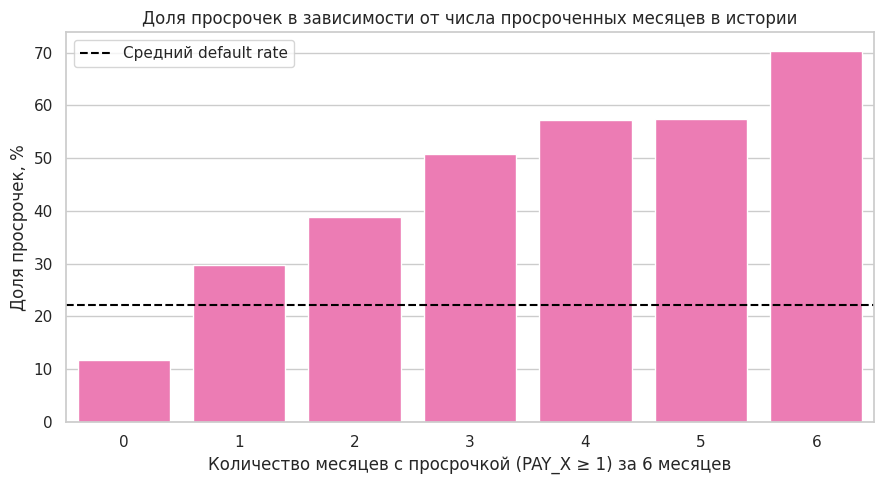

In [11]:
plt.figure(figsize=(9, 5))
sns.barplot(x=n_delinq_summary.index, y=n_delinq_summary["default_rate"] * 100, color="hotpink")
plt.axhline(df["is_default"].mean() * 100, color="black", linestyle="--", label="Средний default rate")
plt.title("Доля просрочек в зависимости от числа просроченных месяцев в истории")
plt.xlabel("Количество месяцев с просрочкой (PAY_X ≥ 1) за 6 месяцев")
plt.ylabel("Доля просрочек, %")
plt.legend()
plt.tight_layout()
plt.show()

График наглядно подтверждает накопительный эффект истории платежей: вероятность невыплаты растет почти линейно от 11.7% (у клиентов без просрочек) до 70.3% (у тех, кто задерживал платежи 6 месяцев подряд). Черная пунктирная линия показывает средний уровень по всей выборке (22.1%), что позволяет увидеть, что клиенты с 1–2 просрочками уже значительно превышают средний риск, а с 3 и более - находятся в критической зоне.



2. Средний срок просрочки по типу истории (stripplot):

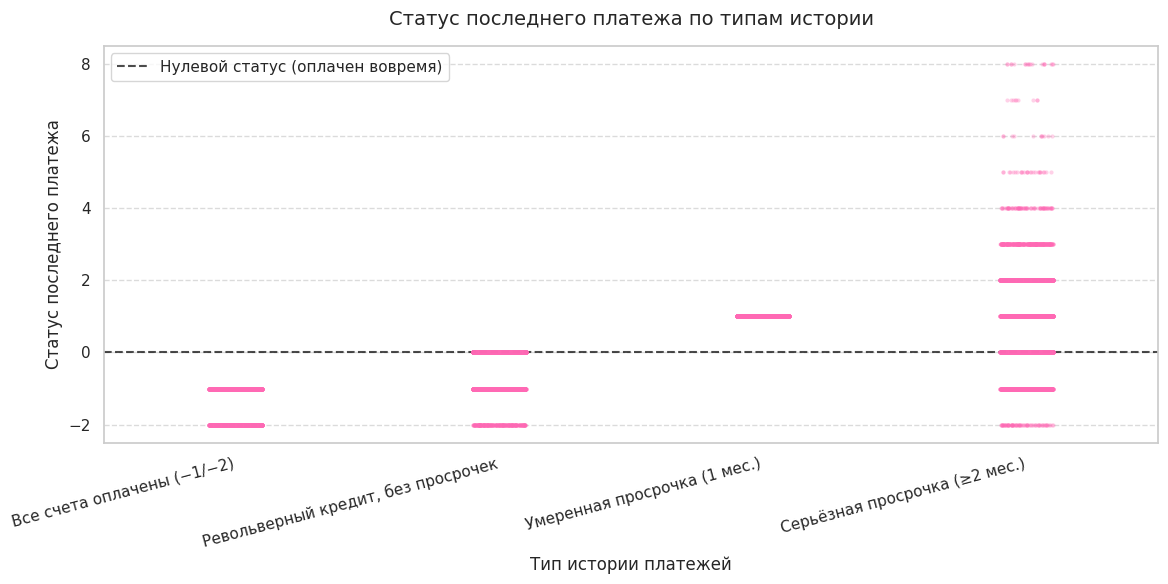

In [12]:
order = [
    "Все счета оплачены (−1/−2)",
    "Револьверный кредит, без просрочек",
    "Умеренная просрочка (1 мес.)",
    "Серьёзная просрочка (≥2 мес.)"
]

plt.figure(figsize=(12, 6))

sns.stripplot(
    data=df,
    x="history_type",
    y="PAY_1",
    order=order,
    color="hotpink",
    size=3,
    alpha=0.3,
    jitter=True
)

plt.axhline(0, color="black", linestyle="--", alpha=0.7, label="Нулевой статус (оплачен вовремя)")

plt.title("Статус последнего платежа по типам истории", fontsize=14, pad=15)
plt.xlabel("Тип истории платежей", fontsize=12)
plt.ylabel("Статус последнего платежа", fontsize=12)

plt.xticks(rotation=15, ha="right", fontsize=11)
plt.yticks(fontsize=11)

plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.legend()
plt.tight_layout()
plt.show()

График наглядно демонстрирует зависимость статуса последнего платежа от типа истории клиента: у добросовестных плательщиков значения стабильно группируются в отрицательной зоне (от -1 до -2), в то время как в группе с серьезными просрочками (≥2 мес.) точки хаотично разбросаны от 0 до 8. Это подтверждает, что клиенты с плохой кредитной историей имеют высокий разброс и склонность к систематическим задержкам платежей, что напрямую связано с риском последующей невыплаты.

3. Риск невыплаты по статусу текущего платежа и истории просрочек

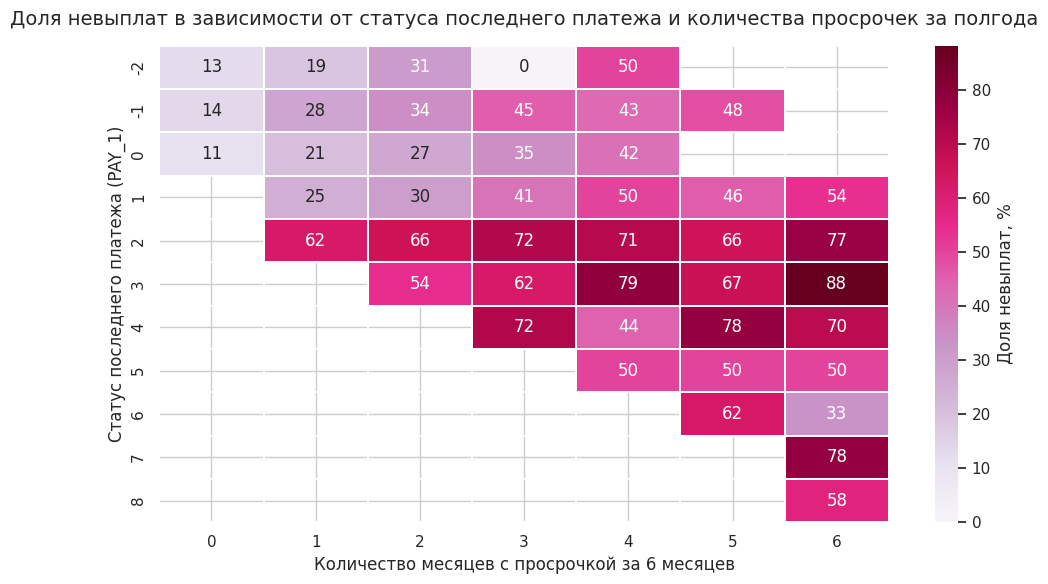

In [13]:
pivot = df.pivot_table(index="PAY_1", columns="n_delinquent_months",
                       values="is_default", aggfunc="mean")

plt.figure(figsize=(10, 6))
sns.heatmap(pivot * 100, cmap="PuRd", annot=True, fmt=".0f", linewidths=.3,
            cbar_kws={"label": "Доля невыплат, %"})

plt.title("Доля невыплат в зависимости от статуса последнего платежа и количества просрочек за полгода", fontsize=14, pad=15)
plt.xlabel("Количество месяцев с просрочкой за 6 месяцев", fontsize=12)
plt.ylabel("Статус последнего платежа (PAY_1)", fontsize=12)

plt.tight_layout()
plt.show()

Тепловая карта наглядно показывает, как свежесть и частота просрочек совместно влияют на риск: в левом верхнем углу (нет просрочек или они старые) концентрация невыплат минимальна (11–15%), а ближе к правому нижнему углу (свежая просрочка + частые задержки) риск достигает критических 88%. При этом заметно, что сам по себе статус последнего платежа без длительной истории (строка PAY_1 = 0 при 0 просрочек) всё равно дает риск в 2 раза выше базового (около 35–45%), а «свежая» задержка (от 1 до 2) мгновенно повышает риск до 62–77%, даже если до этого клиент платил вовремя.

4. Графики для долговой нагрузки (утилизации) и для абсолютного долга

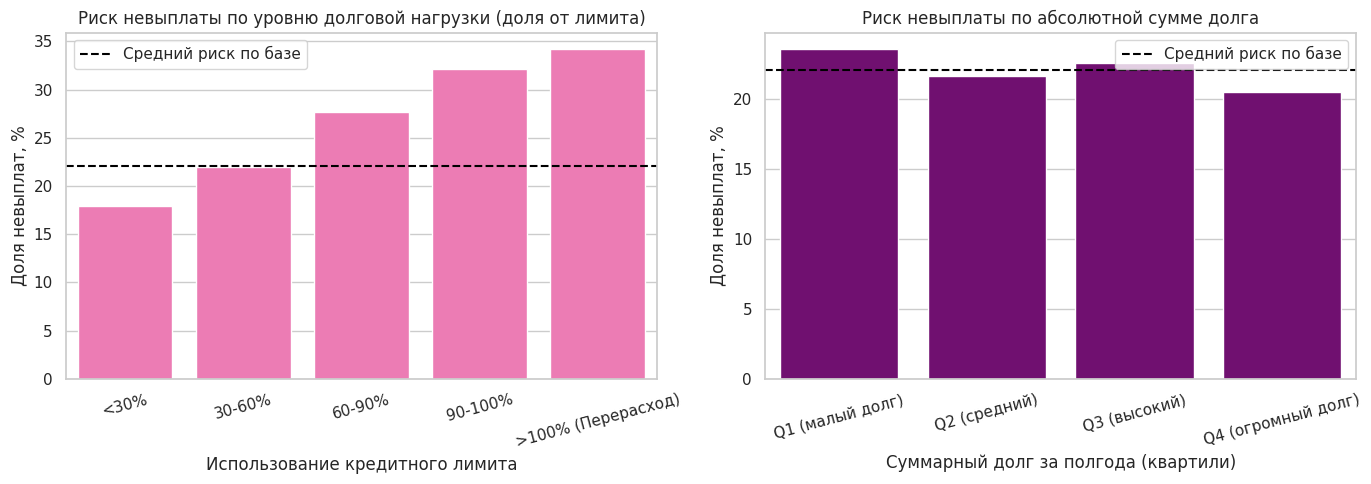

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=util_summary.reset_index(),
    x="util_bin",
    y="default_rate_%",
    color="hotpink",
    ax=axes[0]
)
axes[0].axhline(df["is_default"].mean() * 100, color="black", linestyle="--", label="Средний риск по базе")
axes[0].set_title("Риск невыплаты по уровню долговой нагрузки (доля от лимита)")
axes[0].set_xlabel("Использование кредитного лимита")
axes[0].set_ylabel("Доля невыплат, %")
axes[0].tick_params(axis='x', rotation=15)
axes[0].legend()

sns.barplot(
    data=bill_summary.reset_index(),
    x="bill_quartile",
    y="default_rate_%",
    color="purple",
    ax=axes[1]
)
axes[1].axhline(df["is_default"].mean() * 100, color="black", linestyle="--", label="Средний риск по базе")
axes[1].set_title("Риск невыплаты по абсолютной сумме долга")
axes[1].set_xlabel("Суммарный долг за полгода (квартили)")
axes[1].set_ylabel("Доля невыплат, %")
axes[1].tick_params(axis='x', rotation=15)
axes[1].legend()

plt.tight_layout()
plt.show()

Графики наглядно демонстрируют, что абсолютная сумма долга не является значимым фактором риска: столбцы на правом графике практически одинаковы (около 20–23%), и линия среднего риска проходит прямо через них.

В то же время относительная долговая нагрузка (левый график) показывает четкую восходящую тенденцию: риск невыплаты плавно растет с 17.9% (при использовании <30% лимита) до 34.2% (при перерасходе лимита >100%). Это подтверждает, что для оценки риска важнее не то, сколько человек должен в деньгах, а то, насколько он исчерпал свой кредитный лимит, потеряв финансовый буфер.

## 6. Статистические тесты

1. Критерий Краскела-Уоллиса: сравнение статуса последнего платежа у клиентов с просрочкой и без неё

In [15]:
pay_default = df.loc[df["is_default"], "PAY_1"]
pay_paid = df.loc[~df["is_default"], "PAY_1"]

kw = stats.kruskal(pay_default, pay_paid)
n = len(df)
k = 2
eps2 = max(0, (kw.statistic - k + 1) / (n - k))

print(f"H = {kw.statistic:.1f}, p = {kw.pvalue:.3e}, eps² ≈ {eps2:.4f}")

H = 2561.6, p = 0.000e+00, eps² ≈ 0.0854


H = 2561.6 - значение статистики огромное, что говорит о колоссальной разнице между группами.

p = 0.000 (меньше 0.001) - разница между клиентами, допустившими невыплату, и теми, кто заплатил, статистически значима (мы можем быть уверены, что это не случайность).

eps² ≈ 0.085 - размер эффекта. Значение 0.08–0.09 по шкале Коэна считается средним/умеренным. Это значит, что статус последнего платежа - это не просто формальный признак, он реально и заметно отличает надежных клиентов от проблемных (хотя, разумеется, не является единственным фактором риска).

2. Корреляция Спирмена с фактом невыплаты:

In [16]:
features = {
    "PAY_1": "Статус последнего платежа",
    "n_delinquent_months": "Число просрочек за полгода",
    "payment_ratio": "Доля погашения долга"
}

for col, name in features.items():
    sub = df[[col, "is_default"]].dropna()
    rho, p = stats.spearmanr(sub[col], sub["is_default"])
    print(f"{name:<30} rho = {rho:+.3f}, p = {p:.3e}, n = {len(sub):,}")

Статус последнего платежа      rho = +0.292, p = 0.000e+00, n = 30,000
Число просрочек за полгода     rho = +0.388, p = 0.000e+00, n = 30,000
Доля погашения долга           rho = -0.135, p = 8.287e-118, n = 29,130


Самый сильный предиктор - число просрочек за полгода (rho = +0.388): история важнее текущего момента. Свежий статус платежа (rho = +0.292) тоже значим, но слабее. Доля погашения долга (rho = -0.135) - вспомогательный сигнал (чем больше платит, тем ниже риск). Все связи статистически значимы (p ≈ 0), а n ≈ 29 130 для payment_ratio - потому что клиенты с нулевым счётом дают NaN и выпадают из расчёта.

3. Хи-квадрат Пирсона - связь наличия просрочек в истории с невыплатой

In [17]:
cont = pd.crosstab(df["ever_delinquent"], df["is_default"])

chi2, p_chi2, dof, _ = stats.chi2_contingency(cont)
n_all = cont.to_numpy().sum()
r, c = cont.shape
cramers_v = np.sqrt(chi2 / (n_all * min(r - 1, c - 1)))
print(f"chi2 = {chi2:.1f}, df = {dof}, p = {p_chi2:.3e}")
print(f"V Крамера = {cramers_v:.3f}")
print("\nТаблица сопряжённости:")
print(cont)

chi2 = 3733.5, df = 1, p = 0.000e+00
V Крамера = 0.353

Таблица сопряжённости:
is_default       False  True 
ever_delinquent              
False            17597   2334
True              5767   4302


Связь между наличием просрочек в истории и фактом невыплаты сильная и статистически значимая (chi2 = 3733.5, p ≈ 0, V Крамера = 0.353 - это умеренно-сильная связь).

Из таблицы сопряжённости видно:

Без просрочек в истории (20 000 чел.): невыплата лишь у 12% (2 334).

С просрочками в истории (10 000 чел.): невыплата уже у 43% (4 302) - в 3.5 раза чаще.

Вывод: сам факт наличия просрочки в прошлом — мощный бинарный сигнал риска, но он грубее, чем счётчик месяцев (n_delinquent_months), который даёт более тонкую градацию.

4. Попарное сравнение статуса платежа между типами истории (тест Манна-Уитни, поправка Холма)

In [18]:
groups = df["history_type"].unique()
pairs, pvals = [], []

for i in range(len(groups)):
    for j in range(i + 1, len(groups)):
        a = df.loc[df["history_type"] == groups[i], "PAY_1"].dropna()
        b = df.loc[df["history_type"] == groups[j], "PAY_1"].dropna()
        r = stats.mannwhitneyu(a, b, alternative="two-sided")
        pairs.append((groups[i], groups[j]))
        pvals.append(r.pvalue)

reject, p_adj, _, _ = multipletests(pvals, method="holm")

pair_df = pd.DataFrame({
    "Группа 1": [p[0] for p in pairs],
    "Группа 2": [p[1] for p in pairs],
    "p-значение": pvals,
    "p-значение (Холм)": p_adj,
    "Различия значимы (0.05)": reject
}).sort_values("p-значение (Холм)")

display(pair_df)

,Группа 1,Группа 2,p-значение,p-значение (Холм),Различия значимы (0.05)
0,Серьёзная просрочка (≥2 мес.),"Револьверный кредит, без просрочек",0.000000,0.000000,True
1,Серьёзная просрочка (≥2 мес.),Все счета оплачены (−1/−2),0.000000,0.000000,True
3,"Револьверный кредит, без просрочек",Все счета оплачены (−1/−2),0.000000,0.000000,True
4,"Револьверный кредит, без просрочек",Умеренная просрочка (1 мес.),0.000000,0.000000,True
5,Все счета оплачены (−1/−2),Умеренная просрочка (1 мес.),0.000000,0.000000,True
2,Серьёзная просрочка (≥2 мес.),Умеренная просрочка (1 мес.),0.328447,0.328447,False


Результаты показывают, что все группы клиентов значимо отличаются друг от друга по статусу последнего платежа (p < 0.001), кроме одной пары.

Единственное исключение - «Серьёзная просрочка (≥2 мес.)» и «Умеренная просрочка (1 мес.)» (p = 0.328). Это означает, что если клиент уже имеет текущую задержку, то глубина этой задержки (1 месяц или больше) в рамках нашей классификации не дает статистически значимой разницы в статусе текущего платежа - обе группы уже находятся в зоне высокого риска.

Вывод: разделение клиентов на категории по их истории полностью оправдано: «хорошие» плательщики статистически достоверно отличаются от «плохих», а внутри «плохих» разница между средней и тяжелой просрочкой смазывается.



## 7. Итоговый вывод

**Главный исследовательский вопрос:** *какие группы истории платежей связаны с последующей просрочкой?*

Анализ 30 000 клиентов показал, что история платежей - это ключевой фактор невыплаты, а просрочка в прошлом практически гарантирует высокий риск просрочки в будущем. Ответ на главный вопрос можно сформулировать по четырём осям:

1. **Накопленная история (самая сильная связь):** клиенты с **тремя и более просроченными месяцами** за полгода имеют риск невыплаты **51–70%** (против 11.7% у клиентов без просрочек). Число просрочек (`n_delinquent_months`) коррелирует с фактом невыплаты сильнее всего (`rho = +0.388`) и является самым мощным сигналом риска.
2. **Свежесть просрочки:** **статус последнего месяца (`PAY_1`)** тоже статистически значим (`rho = +0.292`). Клиент с задержкой от 1 месяца имеет риск **34%**, с 2 месяцами — **69%**. Просрочка «здесь и сейчас» опаснее, чем старая, но накопленный счётчик важнее одиночного статуса.
3. **Платёжная дисциплина:** клиенты, гасящие **менее 5% долга**, просрочивают в **26–36%** случаев, тогда как платящие **более 50%** — лишь в **15%**.
4. **Долговая нагрузка (относительная, а не абсолютная):** абсолютная сумма долга сама по себе почти не влияет на риск (разница между группами всего 2–3 п.п.). Однако **доля использования кредитного лимита** — важный фактор: при использовании <30% лимита риск составляет **17.9%**, а при перерасходе (>100%) вырастает до **34.2%**. Клиенты, упёршиеся в потолок лимита, теряют финансовый буфер и статистически чаще допускают невыплаты.

**Статистическое подтверждение:** все выводы проверены тестами. Краскел-Уоллис показал колоссальные различия в распределениях (`H = 2561.6`, `p ≈ 0`), хи-квадрат доказал, что наличие прошлых просрочек повышает риск невыплаты в 3.5 раза (`V Крамера = 0.353`), а тест Манна-Уитни с поправкой Холма подтвердил, что выделенные группы типов истории статистически значимо отличаются друг от друга.

**Практический вывод для бизнеса:** самая рискованная группа - клиенты, имеющие **свежую просрочку (1–2 месяца) в сочетании с 3+ просрочками в истории** (риск 62–77%), а также клиенты, **исчерпавшие свой кредитный лимит более чем на 100%**. Самая надёжная группа - те, кто **гасит счета полностью, не имеет задержек и использует менее 30% лимита** (риск ~11–17%).